# Rethinking Nightingale's Chart

<div style="margin-top:1rem;">
DS 2023 | Communicating with Data    
</div>

## Overview

Florence Nightingale's polar plot is one of the most discussed visualizations in history.

It was not, however, the most statistically transparent way to show her data.

The code below generates seven alternative charts of the same numbers: stacked bars, grouped bars, a line chart, area charts, a pie chart, and a mean bar chart.

Every one of them is accurate in terms of its fidelity to the data.

None of them changed British public health policy.

This activity asks you to explain why.

## Background

After the Crimean War, Nightingale needed to convince the British War Office, Parliament, and Queen Victoria to reform military sanitation.

Her audience had poor data literacy and actively discounted statistical arguments.
The War Office had already published its own reports using conventional line and bar charts — reports that were read, filed, and ignored.

Nightingale's response was not to make a cleaner version of those charts.
It was to make something that looked nothing like them.
She packaged her diagrams in slim folios alongside pointed prose and structured her argument in three acts:

1. **Problem** — soldiers are dying at catastrophic rates.
2. **Cause** — most deaths are from preventable disease, not combat wounds.
3. **Solution** — sanitation reforms demonstrably reduced those deaths.

The polar plot was not a standalone artifact. It was one move in that sequence.

## Setup

Run the two cells below to load the data and generate the `RW` table used for all the charts.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import math

In [3]:
data_str = """YEAR,MONTH,STRENGTH,DISEASE,INJURY,OTHER,DISEASE_RATE,INJURY_RATE,OTHER_RATE
1854, 4, 8571, 1, 0, 5, 1.4, 0.0, 7.0
1854, 5, 23333, 12, 0,9, 6.2, 0.0, 4.6
1854, 6, 28333, 11, 0, 6, 4.7, 0.0, 2.5
1854, 7, 28722, 359, 0, 23, 150.0, 0.0, 9.6
1854, 8, 30246, 828, 1, 30, 328.5, 0.4, 11.9
1854, 9, 30290, 788, 81, 70, 312.2, 32.1, 27.7
1854, 10, 30643, 503, 132, 128, 197.0, 51.7, 50.1
1854, 11, 29736, 844, 287, 106, 340.6, 115.8, 42.8
1854, 12, 32779, 1725, 114, 131, 631.5, 41.7, 48.0
1855, 1, 32393, 2761, 83, 324, 1022.8, 30.7, 120.0
1855, 2, 30919, 2120, 42, 361, 822.8, 16.3, 140.1
1855, 3, 30107, 1205, 32, 172, 480.3, 12.8, 68.6
1855, 4, 32252, 477, 48, 57, 177.5, 17.9, 21.2
1855, 5, 35473, 508, 49, 37, 171.8, 16.6, 12.5
1855, 6, 38863, 802, 209, 31, 247.6, 64.5, 9.6
1855, 7, 42647, 382, 134, 33, 107.5, 37.7, 9.3
1855, 8, 44614, 483, 164, 25, 129.9, 44.1, 6.7
1855, 9, 47751, 189, 276, 20, 47.5, 69.4, 5.0
1855, 10, 46852, 128, 53, 18, 32.8, 13.6, 4.6
1855, 11, 37853, 178, 33, 32, 56.4, 10.5, 10.1
1855, 12, 43217, 91, 18, 28, 25.3, 5.0, 7.8
1856, 1, 44212, 42, 2, 48, 11.4, .5, 13.0
1856, 2, 43485, 24, 0, 19, 6.6, 0.0, 5.2
1856, 3, 46140, 15, 0, 35, 3.9, 0.0, 9.1"""

# Build the dataframe
df = pd.read_csv(io.StringIO(data_str))
df = df.reset_index(drop=True).set_index(['YEAR', 'MONTH'])

# Reshape rates to long form
RATES = df[['DISEASE_RATE', 'INJURY_RATE', 'OTHER_RATE']].copy()
RATES.columns = ['D', 'I', 'O']
RATES = RATES.stack().to_frame('rate')
RATES.index.names = ['YEAR', 'MONTH', 'CAUSE']

# Radius (needed for DATE index)
def get_radius(A, slices=12, factor=1):
    B = (360 / slices) / 2
    return math.sqrt(A / B) * factor

RATES['radius'] = RATES['rate'].apply(get_radius)
RADIUS = RATES.radius.unstack()

# Date labels
month_names = 'JAN FEB MAR APR MAY JUN JUL AUG SEP OCT NOV DEC'.split()
DATE = pd.DataFrame(index=RADIUS.index)
DATE['seq_num'] = list(range(12)) * 2
DATE['angle'] = 2 * np.pi * DATE.seq_num / 12
DATE['label'] = DATE.apply(lambda x: f"{month_names[x.name[1]-1]} {x.name[0]}", axis=1)

# Cause metadata
CAUSE = pd.DataFrame(index=['D', 'I', 'O'])
CAUSE['color'] = ['lightblue', 'pink', 'gray']
CAUSE['name'] = ['disease', 'injury', 'other']
CAUSE['order'] = [2, 0, 1]

# RW: rates in wide form, labeled by date, columns named by cause
cause_order = CAUSE.sort_values('order').index.tolist()  # ['I', 'O', 'D']
RW = RATES.rate.unstack()[cause_order].join(DATE.label).reset_index(drop=True).set_index('label')
RW.columns = CAUSE.loc[RW.columns, 'name']
RW.columns.name = 'cause'
RW.index.name = 'date'

color = CAUSE.loc[cause_order, 'color'].values
RW

cause,injury,other,disease
date,,,
APR 1854,0.0,7.0,1.4
MAY 1854,0.0,4.6,6.2
JUN 1854,0.0,2.5,4.7
JUL 1854,0.0,9.6,150.0
AUG 1854,0.4,11.9,328.5
SEP 1854,32.1,27.7,312.2
OCT 1854,51.7,50.1,197.0
NOV 1854,115.8,42.8,340.6
DEC 1854,41.7,48.0,631.5


## The Charts

Run each cell below to produce seven alternative visualizations of the same data.

They are labeled **A through G** for reference in the activity.

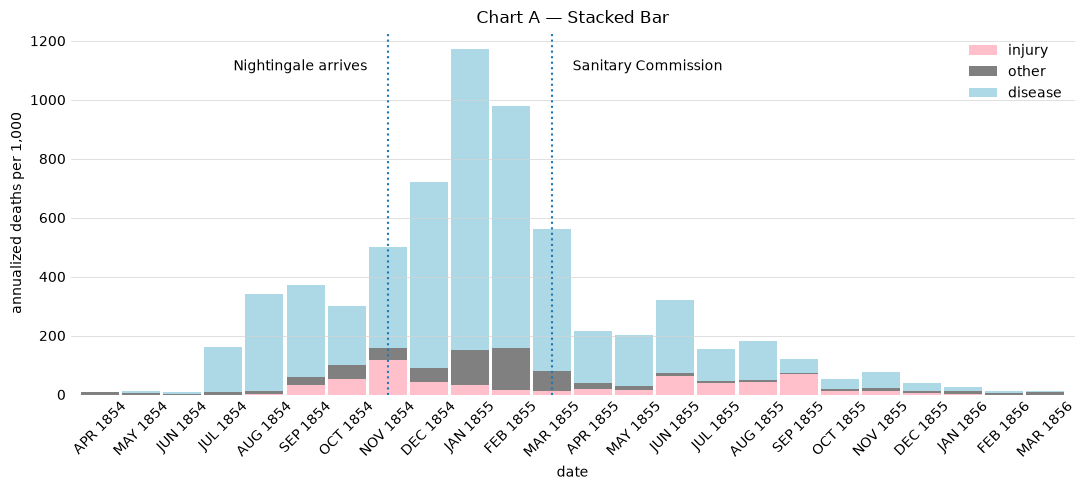

In [4]:
# Chart A — Stacked Bar
fig, ax = plt.subplots(figsize=(11, 5))
RW.plot.bar(stacked=True, rot=45, ax=ax, color=color, width=.925)

label_y = 1100
i1 = RW.index.get_loc('NOV 1854')
i2 = RW.index.get_loc('MAR 1855')
ax.axvline(i1, ls='dotted')
ax.annotate('Nightingale arrives', xy=(i1, label_y), xytext=(i1 - .5, label_y), ha='right')
ax.axvline(i2, ls='dotted')
ax.annotate('Sanitary Commission', xy=(i2, label_y), xytext=(i2 + .5, label_y), ha='left')

ax.set_ylabel('annualized deaths per 1,000')
ax.set_title('Chart A — Stacked Bar')
ax.legend(frameon=False)
sns.despine(left=True, bottom=True)
ax.tick_params(axis='both', length=0)
ax.grid(axis='y', color='lightgray', linewidth=0.5)
plt.tight_layout()
plt.show()

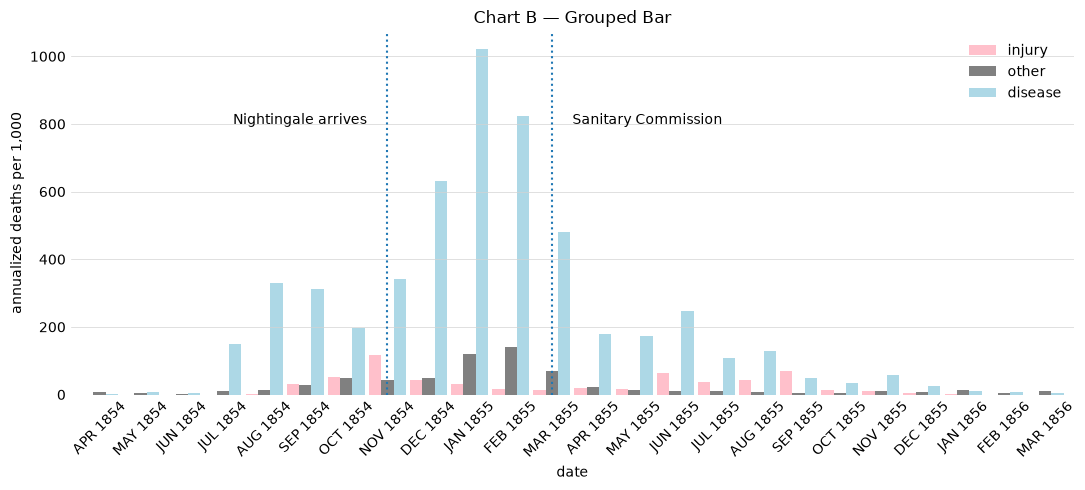

In [5]:
# Chart B — Grouped Bar
fig, ax = plt.subplots(figsize=(11, 5))
RW.plot.bar(stacked=False, rot=45, ax=ax, color=color, width=.9)

label_y = 800
i1 = RW.index.get_loc('NOV 1854')
i2 = RW.index.get_loc('MAR 1855')
ax.axvline(i1, ls='dotted')
ax.annotate('Nightingale arrives', xy=(i1, label_y), xytext=(i1 - .5, label_y), ha='right')
ax.axvline(i2, ls='dotted')
ax.annotate('Sanitary Commission', xy=(i2, label_y), xytext=(i2 + .5, label_y), ha='left')

ax.set_ylabel('annualized deaths per 1,000')
ax.set_title('Chart B — Grouped Bar')
ax.legend(frameon=False)
sns.despine(left=True, bottom=True)
ax.tick_params(axis='both', length=0)
ax.grid(axis='y', color='lightgray', linewidth=0.5)
plt.tight_layout()
plt.show()

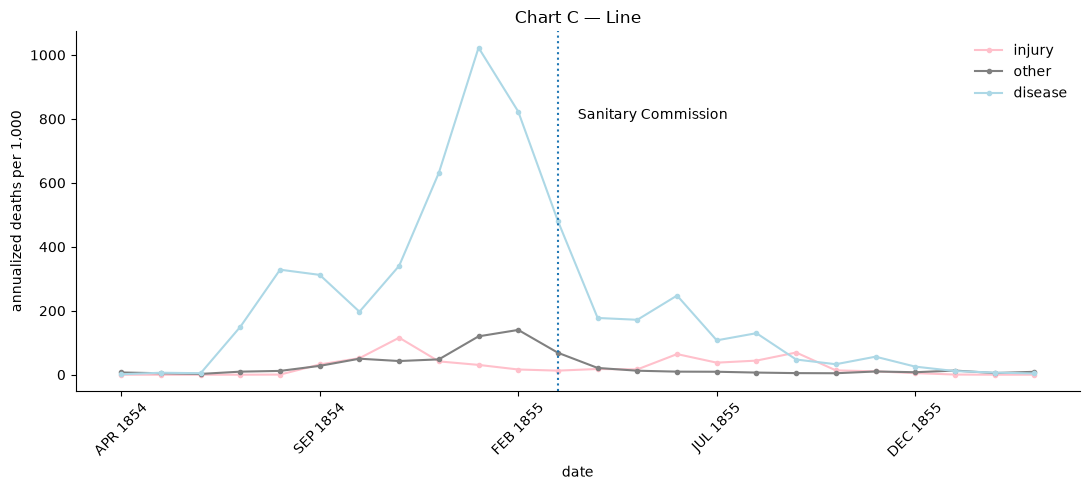

In [6]:
# Chart C — Line
fig, ax = plt.subplots(figsize=(11, 5))
RW.plot.line(ax=ax, rot=45, color=color, style='.-')

i2 = RW.index.get_loc('MAR 1855')
ax.axvline(i2, ls='dotted')
ax.annotate('Sanitary Commission', xy=(i2, 800), xytext=(i2 + .5, 800), ha='left')

ax.set_ylabel('annualized deaths per 1,000')
ax.set_title('Chart C — Line')
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

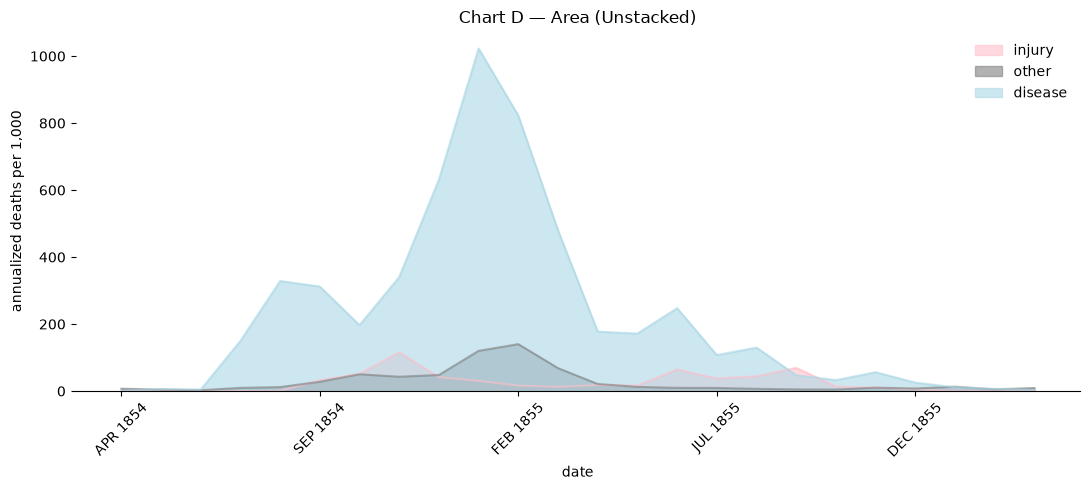

In [7]:
# Chart D — Area (Unstacked)
fig, ax = plt.subplots(figsize=(11, 5))
RW.plot.area(ax=ax, rot=45, color=color, stacked=False, alpha=0.6)
ax.set_ylabel('annualized deaths per 1,000')
ax.set_title('Chart D — Area (Unstacked)')
ax.legend(frameon=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

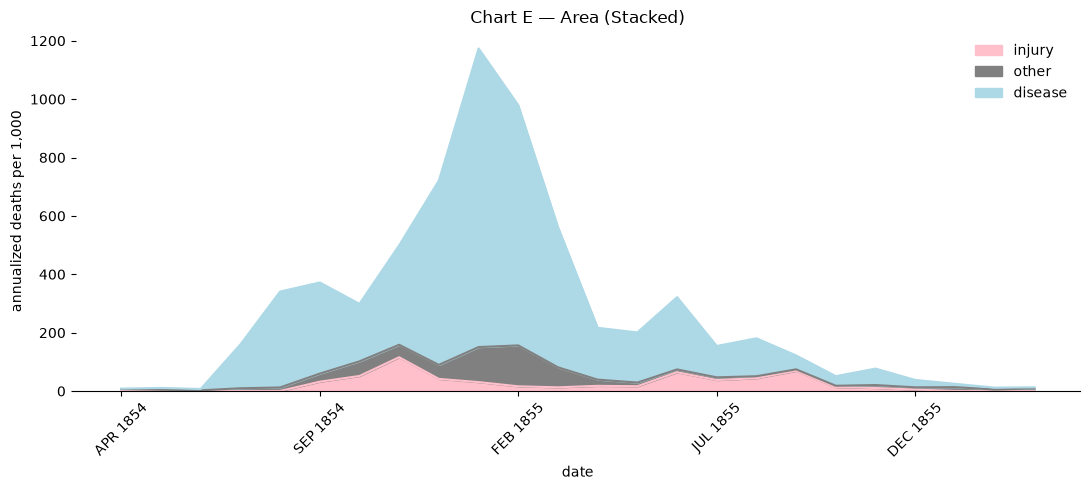

In [8]:
# Chart E — Area (Stacked)
fig, ax = plt.subplots(figsize=(11, 5))
RW.plot.area(ax=ax, rot=45, color=color, stacked=True)
ax.set_ylabel('annualized deaths per 1,000')
ax.set_title('Chart E — Area (Stacked)')
ax.legend(frameon=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

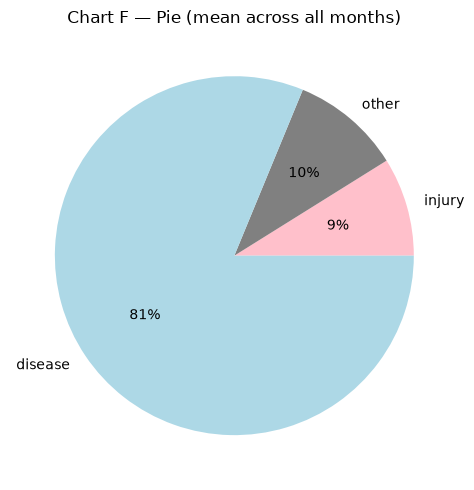

In [9]:
# Chart F — Pie (mean values across all months)
fig, ax = plt.subplots(figsize=(5, 5))
RW.mean().plot.pie(ax=ax, colors=color, autopct='%1.0f%%')
ax.set_title('Chart F — Pie (mean across all months)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

/var/folders/fb/hhf80dqn5x190kxk7_y8557r0000gq/T/ipykernel_89782/4169694704.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False)


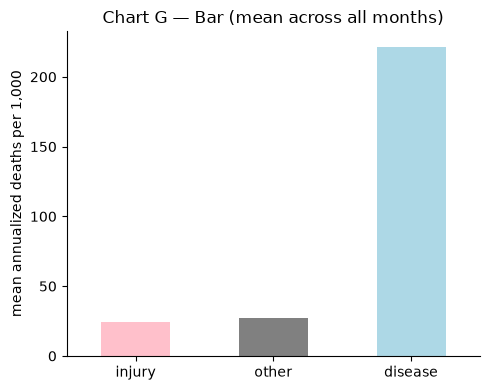

In [10]:
# Chart G — Bar (mean values across all months)
fig, ax = plt.subplots(figsize=(5, 4))
RW.mean().plot.bar(ax=ax, rot=0, color=color)
ax.set_xlabel('')
ax.set_ylabel('mean annualized deaths per 1,000')
ax.set_title('Chart G — Bar (mean across all months)')
ax.legend(frameon=False)
sns.despine()
plt.tight_layout()
plt.show()